**ESPECTRO-NCh433of2026**

 ESPECTROS SÍSMICOS — NCh433:2026 
 Zona Sísmica : 3 -> A0 = 0.40 g (3.9227 m/s²)
 Tipo Suelo   : C -> S=1.05, T0=0.4 s, T'=0.45 s, n=1.4, p=1.6
 Categoría    : II (I = 1.00) | R0 = 11.0 | R = 7.0
 Corte Basal  : Cmín = 0.0700 g | Cmáx = 0.1470 g
--------------------------------------------------------------------
 Espectro X   : Tx = 0.680 s | R*(X) = 7.6786
 Espectro Y   : Ty = 0.540 s | R*(Y) = 7.0612


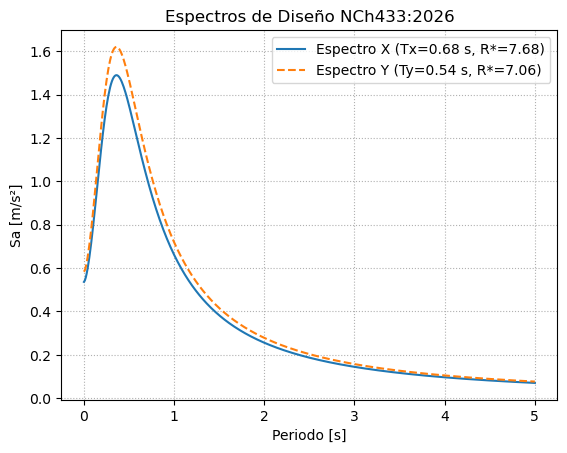

In [ ]:
# Salida Sa en [m/s²] para Scale Factor = 1.

import os
import numpy as np
import matplotlib.pyplot as plt

# Carpeta de guardado de espectros
RUTA_SALIDA = r"COPIA AQUI LA RUTA DESEADA PARA GUARDAR LOS ARCHIVOS TXT" 

# ==============================================================================
# 1. VARIABLES DE CONFIGURACIÓN GENERAL DEL ESPECTRO SÍSMICO (NCh433:2026)
# ==============================================================================

Tx = 0.68                   # Periodo fundamental en dirección X [s] (SAP2000)
Ty = 0.54                   # Periodo fundamental en dirección Y [s] (SAP2000)
R0 = 11.0                   # Factor de modificación de respuesta modal (Tabla 5) 
R = 7.0                     # Factor de modificación de respuesta estático (Tabla 5) 

zona_sismica = 3            # Tabla 7: 1, 2 o 3
tipo_suelo = "C"            # Tabla 8: 'A', 'B', 'C', 'D', 'E'
categoria_ocupacion = "II"  # Tabla 6: 'I', 'II', 'III', 'IV'
factor_importancia = None   # None usa Tabla 6; o valor manual (ej. 1.2)

g = 9.80665                 # Gravedad [m/s²]
T_min = 0.00                # Periodo inicial [s]
T_max = 5.00                # Periodo final [s]
dT = 0.01                   # Incremento de periodo [s]
aplicar_limites_C = False   # True acota la curva entre I*Cmín*g e I*Cmáx*g

# Diccionarios de parámetros normativos, direcciones y exportación
parametros_normativos = {
    # Tabla 6: Factor de importancia I [-]
    "I": {"I": 0.6, "II": 1.0, "III": 1.2, "IV": 1.2},
    # Tabla 7: Aceleración efectiva máxima A0 como fracción de g        
    "A0": {1: 0.20, 2: 0.30, 3: 0.40},
    # Tabla 8: Parámetros según tipo de sitio (S [-], T0 [s], Tp [s], n [-], p [-])
    "suelos": {
        "A": {"S": 0.90, "T0": 0.15, "Tp": 0.20, "n": 1.00, "p": 2.0},
        "B": {"S": 1.00, "T0": 0.30, "Tp": 0.35, "n": 1.33, "p": 1.5},
        "C": {"S": 1.05, "T0": 0.40, "Tp": 0.45, "n": 1.40, "p": 1.6},
        "D": {"S": 1.20, "T0": 0.75, "Tp": 0.85, "n": 1.80, "p": 1.0},
        "E": {"S": 1.30, "T0": 1.20, "Tp": 1.35, "n": 1.80, "p": 1.0},
    },
    # Tabla 9: Factor f para C_max = f * S * A0 / g [-]
    "f_Cmax": {2.0: 0.90, 3.0: 0.60, 4.0: 0.55, 5.5: 0.40, 6.0: 0.35}
}

parametros_x = {"Tx": Tx, "R0": R0, "R": R}  # Dirección X
parametros_y = {"Ty": Ty, "R0": R0, "R": R}  # Dirección Y

config_exportacion = {"ruta_salida": RUTA_SALIDA, "archivo_x": "Espectro_X.txt", "archivo_y": "Espectro_Y.txt", "separador": "\t", "dec_T": 4, "dec_Sa": 6}

# ==============================================================================
# 2. CÁLCULO DE ESPECTROS X e Y
# ==============================================================================

I = factor_importancia or parametros_normativos["I"][categoria_ocupacion]
A0_g = parametros_normativos["A0"][zona_sismica]
A0 = A0_g * g  # Aceleración efectiva máxima en [m/s²]

s_dat = parametros_normativos["suelos"][tipo_suelo]
S, T0, Tp, n, p = s_dat["S"], s_dat["T0"], s_dat["Tp"], s_dat["n"], s_dat["p"]

# Vector de periodos incluyendo puntos notables exactos (T0, T', Tx, Ty)
malla_base = np.arange(T_min, T_max + dT / 2, dT)
notables = [t for t in (T0, Tp, Tx, Ty) if T_min <= t <= T_max]
T = np.unique(np.round(np.concatenate([malla_base, notables]), 6))

# Ecuación (9): Factor de amplificación dinámica alpha(Tn) [-]
alpha = (1.0 + 4.5 * (T / T0) ** p) / (1.0 + (T / T0) ** 3)

# Ecuación (10): Factores de reducción R* usando directamente Tx, Ty y R0 [-]
Rx_ast = 1.0 + Tx / (0.10 * T0 + Tx / R0)
Ry_ast = 1.0 + Ty / (0.10 * T0 + Ty / R0)

# Ecuación (8): Ordenadas espectrales de diseño Sa_x y Sa_y en [m/s²]
Sa_x = (I * S * A0 * alpha) / Rx_ast
Sa_y = (I * S * A0 * alpha) / Ry_ast

# Límites de corte basal C_min y C_max (Cláusula 6.3.6 y Tabla 9)
f_cmax = 0.35 if R >= 6.0 else parametros_normativos["f_Cmax"].get(R, 2.5 / (R + 0.8))
C_min_g, C_max_g = (S * A0_g) / 6.0, f_cmax * S * A0_g

if aplicar_limites_C:
    Sa_x = np.clip(Sa_x, I * C_min_g * g, I * C_max_g * g)
    Sa_y = np.clip(Sa_y, I * C_min_g * g, I * C_max_g * g)

# ==============================================================================
# 3. EXPORTACIÓN DE ARCHIVOS TXT, RESUMEN Y GRÁFICO
# ==============================================================================

os.makedirs(config_exportacion["ruta_salida"], exist_ok=True)
ruta_x = os.path.join(config_exportacion["ruta_salida"], config_exportacion["archivo_x"])
ruta_y = os.path.join(config_exportacion["ruta_salida"], config_exportacion["archivo_y"])

sep, dec_T, dec_Sa = config_exportacion["separador"], config_exportacion["dec_T"], config_exportacion["dec_Sa"]

for ruta, sa in [(ruta_x, Sa_x), (ruta_y, Sa_y)]:
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(f"T(s){sep}Sa\n")
        for t_val, sa_val in zip(T, sa):
            f.write(f"{t_val:.{dec_T}f}{sep}{sa_val:.{dec_Sa}f}\n")

print("=" * 68)
print(" ESPECTROS SÍSMICOS — NCh433:2026 ")
print("=" * 68)
print(f" Zona Sísmica : {zona_sismica} -> A0 = {A0_g:.2f} g ({A0:.4f} m/s²)")
print(f" Tipo Suelo   : {tipo_suelo} -> S={S}, T0={T0} s, T'={Tp} s, n={n}, p={p}")
print(f" Categoría    : {categoria_ocupacion} (I = {I:.2f}) | R0 = {R0} | R = {R}")
print(f" Corte Basal  : Cmín = {C_min_g:.4f} g | Cmáx = {C_max_g:.4f} g")
print("-" * 68)
print(f" Espectro X   : Tx = {Tx:.3f} s | R*(X) = {Rx_ast:.4f}")
print(f" Espectro Y   : Ty = {Ty:.3f} s | R*(Y) = {Ry_ast:.4f}")
print("=" * 68)

# Despliegue obligatorio del gráfico espectral
plt.plot(T, Sa_x, label=f"Espectro X (Tx={Tx} s, R*={Rx_ast:.2f})")
plt.plot(T, Sa_y, "--", label=f"Espectro Y (Ty={Ty} s, R*={Ry_ast:.2f})")
plt.xlabel("Periodo [s]")
plt.ylabel("Sa [m/s²]")
plt.title("Espectros de Diseño NCh433:2026")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()